Import libraries and functions

In [ ]:
import time
from codebase_0 import CANN, MLP, cann_training_loop, mlp_train_loop, DeviceLoader, set_seed
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import numpy as np
from torch import nn

from gamma_bcann_vi import (
    gamma_build_bcann_guide, GammaBCANN, gamma_fit_glm_mle,
    gamma_bcann_svi_training_loop, GammaCANN, gamma_cann_training_loop,
    gamma_deviance, gamma_evaluate_bcann
)
import torch
import pyro

seed = 42
set_seed(seed)
pyro.clear_param_store()


Load data and split train/validation/test sets

In [44]:
device = torch.device("cuda")

torch.set_default_device("cpu")

dataset = pd.read_csv("freMTPL2sev_transformed.csv", index_col= 0) 
y = torch.tensor(dataset["ClaimAmount"].to_numpy(), dtype=torch.float32)
weights = torch.ones(len(y)) 
X = torch.tensor(
    dataset.drop(columns=["IDpol", "Exposure","ClaimAmount"]).to_numpy(), 
    dtype=torch.float32
)   # 48 columns

# Learning-test set split
X_learn, X_test, y_learn, y_test, w_learn, w_test = train_test_split(
    X, y, weights, test_size= 0.1, random_state= seed
)

# Training-CV set split
X_train, X_val, y_train, y_val, w_train, w_val = train_test_split(
    X_learn, y_learn, w_learn, test_size= 0.1, random_state= seed
)

learn_scaler = MinMaxScaler().fit(X_learn)
X_learn = learn_scaler.transform(X_learn)
X_test = learn_scaler.transform(X_test)

train_scaler = MinMaxScaler().fit(X_train)
X_train = train_scaler.transform(X_train)
X_val = train_scaler.transform(X_val)

def T(a):
    return torch.as_tensor(a, dtype=torch.float32, device=device)

X_train, X_val, X_learn, X_test = map(T, (X_train, X_val, X_learn, X_test))
y_train, y_val, y_learn, y_test = map(T, (y_train, y_val, y_learn, y_test))
w_train, w_val, w_learn, w_test = map(T, (w_train, w_val, w_learn, w_test))

torch.set_default_device(device)
train_loader = DeviceLoader(
        X_train, y_train, w_train,
        batch_size = 2056,
        shuffle= True
)
val_loader = DeviceLoader(
        X_val, y_val, w_val,
        batch_size= 10000
)
learn_loader = DeviceLoader(
        X_learn, y_learn, w_learn,
        batch_size= 2056
)
test_loader = DeviceLoader(
        X_test, y_test, w_test,
        batch_size= 10000
)

# GLM + CANN training

GLM/MLE fitting

In [6]:
glm_mle = gamma_fit_glm_mle(X_train, y_train, random_state=seed)
with torch.no_grad():
    glm_val_dev = gamma_deviance(y_true=y_val, y_pred=X_val @ glm_mle[0].T.squeeze(-1) + glm_mle[1]).item()
    print(f"GLM (MLE) val deviance: {glm_val_dev:.4f}")

GLM (MLE) val deviance: 1.5342


In [7]:
with torch.no_grad():
    glm_val_dev = gamma_deviance(y_true=y_train, y_pred=X_train @ glm_mle[0].T.squeeze(-1) + glm_mle[1]).item()
    print(f"GLM (MLE) training deviance: {glm_val_dev:.4f}")

GLM (MLE) training deviance: 1.5159


CANN fitting

In [45]:
network_architecture = [20, 15, 10]
gamma_cann = GammaCANN(
    in_features= 48, 
    neural_net_params= {"hidden_activation_nodes": network_architecture},
    random_state= seed
).to(device)

In [16]:
time_0 = time.time()
cann_history = gamma_cann_training_loop(
    gamma_cann,
    nn_optimiser= torch.optim.Adam,
    nn_optim_params = {"lr": 5e-3},
    nn_epochs= 58,
    train_loader= train_loader,
    val_loader = val_loader,
    random_state = 42,
    device = device,
    early_stop_params= {"patience": 100}
)
time_1 = time.time()
print(time_1 - time_0)

Epoch 1 | train loss: 1.5170 | val loss: 1.5341
2.0415384769439697


# BCANN training

In [22]:
pyro.clear_param_store()

gamma_bcann = GammaBCANN(
    in_features= 48,
    neural_net_params={"hidden_activation_nodes": network_architecture,
                        "hidden_activations": nn.Tanh,
                        "prior_scale": 1},
).to(device)
glm_mle = gamma_fit_glm_mle(X_train, y_train, random_state=seed)
guide = gamma_build_bcann_guide(gamma_bcann, X_train[:256], y_train[:256], glm_mle=glm_mle, rank=10)

Early stopping

In [20]:
bcann_history = gamma_bcann_svi_training_loop(
        gamma_bcann, guide, 
        train_loader, 
        val_loader,
        n_epochs=300, 
        lr=5e-3, 
        val_every=5, 
        patience=10, 
        random_state=seed, 
        device = device)


Shape warm-up: alpha held at 0.058 for 20 epochs


Epoch 1 | -ELBO/n: 10.0376 | train deviance: 1.5177 | val deviance: 1.5244 | alpha (median): 0.058 [warm-up]
Epoch 25 | -ELBO/n: 9.9179 | train deviance: 1.5182 | val deviance: 1.5249 | alpha (median): 0.060
Epoch 50 | -ELBO/n: 9.8378 | train deviance: 1.5201 | val deviance: 1.5297 | alpha (median): 0.069
Epoch 75 | -ELBO/n: 9.7237 | train deviance: 1.5200 | val deviance: 1.5257 | alpha (median): 0.079
Early stopping at epoch 90. Best val deviance 1.5217 at epoch 40


In [ ]:
time_0 = time.time()
bcann_history = gamma_bcann_svi_training_loop(
        gamma_bcann, guide, 
        train_loader, 
        val_loader,
        n_epochs=40, 
        lr=5e-3, 
        val_every=5, 
        patience=25, # this means validation set is test every 5 times, and early stopping only implements when the loss doesn't decrease after 25 checks (5*25 = 125 epochs > 40)
        random_state=seed, 
        device = device)
time_1 = time.time()
print(time_1 - time_0)

Shape warm-up: alpha held at 0.058 for 20 epochs


Epoch 1 | -ELBO/n: 10.0376 | train deviance: 1.5177 | val deviance: 1.5244 | alpha (median): 0.058 [warm-up]
Epoch 25 | -ELBO/n: 9.9179 | train deviance: 1.5182 | val deviance: 1.5249 | alpha (median): 0.060
55.804863691329956


In [24]:
print(f"Last epoch training score: {bcann_history.get("train_deviance")[-1]}")
print(f"Last epoch validation score: {bcann_history.get("val_deviance")[-1]}")

Last epoch training score: 1.5187526941299438
Last epoch validation score: 1.521723985671997


# Train on learn set to get performance on test set

In [5]:
pyro.clear_param_store()
network_architecture = [20, 15, 10]
best_gamma_bcann = GammaBCANN(
    in_features= 48,
    neural_net_params={"hidden_activation_nodes": network_architecture,
                        "hidden_activations": nn.Tanh,
                        "prior_scale": 1},
).to(device)
glm_mle = gamma_fit_glm_mle(X_learn, y_learn, random_state=seed)
guide = gamma_build_bcann_guide(best_gamma_bcann, X_learn[:256], y_learn[:256], glm_mle=glm_mle, rank=10)

time_0 = time.time()
bcann_history = gamma_bcann_svi_training_loop(
        best_gamma_bcann, guide, 
        learn_loader, 
        val_loader,
        n_epochs=40, 
        lr=5e-3, 
        val_every=40, # ensure all 40 epochs run with out validation -> faster
        patience=25, 
        random_state=seed, 
        device = device)
time_1 = time.time()
print(time_1 - time_0)

Shape warm-up: alpha held at 0.058 for 20 epochs
Epoch 1 | -ELBO/n: 10.0396 | train deviance: 1.5165 | val deviance: 1.4816 | alpha (median): 0.058 [warm-up]
61.6715943813324


In [46]:
# write to disk 

torch.save({
    "recipe": {
        "cls": "GammaBCANN",
        "kwargs": dict(in_features= 48,
                        neural_net_params={"hidden_activation_nodes": network_architecture, "hidden_activations": "Tanh"}),
    },
    "guide_builder": "gamma_build_bcann_guide",
    "guide_kwargs": dict(rank=10),                     # + tau_init for the horseshoe builders
    "guide_state": {k: v.detach().cpu() for k, v in guide.state_dict().items()},
}, "runs/gamma_bcann_vi.pt")

In [ ]:
# GammaBCANN with Gaussian prior on test set
gamma_evaluate_bcann(best_gamma_bcann, guide, test_loader, 200, device = device)

1.8245272636413574

In [9]:
network_architecture = [20, 15, 10]
gamma_cann = GammaCANN(
    in_features= 48, 
    neural_net_params= {"hidden_activation_nodes": network_architecture},
    random_state= seed
).to(device)
time_0 = time.time()
cann_history = gamma_cann_training_loop(
    gamma_cann,
    nn_optimiser= torch.optim.Adam,
    nn_optim_params = {"lr": 5e-3},
    nn_epochs= 29,
    train_loader= learn_loader,
    val_loader = val_loader, # passed in but not used since patience is 100
    random_state = 42,
    device = device,
    early_stop_params= {"patience": 100}
)
time_1 = time.time()
print(time_1 - time_0)

Epoch 1 | train loss: 1.5180 | val loss: 1.4806
2.285512685775757


In [ ]:
# CANN on test set
gamma_deviance(y_pred = gamma_cann(X_test), y_true= y_test)

tensor(1.8606, device='cuda:0', grad_fn=<MeanBackward0>)

In [42]:
best_glm_mle = gamma_fit_glm_mle(X_learn, y_learn, random_state=seed)
with torch.no_grad():
    glm_test_dev = gamma_deviance(y_true=y_test, y_pred=X_test @ best_glm_mle[0].T.squeeze(-1) + best_glm_mle[1]).item()
    print(f"GLM (MLE) test deviance: {glm_test_dev:.4f}")

GLM (MLE) test deviance: 1.8324


# Graphing

In [5]:
import matplotlib.pyplot as plt

In [7]:
# read back
import json
with open("plotting_json/gamma_horseshoe_bcann.json") as f:
    horseshoe_history_full = json.load(f) # bcann with horseshoe prior 

with open("plotting_json/gamma_bcann_full.json") as f:
    bcann_history_full = json.load(f) # bcann with diagonal gaussian prior

In [37]:
pyro.clear_param_store()

bcann_gaussian_prior = GammaBCANN(
    in_features= 48,
    neural_net_params={"hidden_activation_nodes": network_architecture,
                        "hidden_activations": nn.Tanh,
                        "prior_scale": 1},
).to(device)
glm_mle = gamma_fit_glm_mle(X_train, y_train, random_state=seed)
guide = gamma_build_bcann_guide(bcann_gaussian_prior, X_train[:256], y_train[:256], glm_mle=glm_mle, rank=10)

bcann_history_full = gamma_bcann_svi_training_loop(
        bcann_gaussian_prior, guide, 
        train_loader, 
        val_loader,
        n_epochs=300, 
        lr=5e-3, 
        val_every=1, # full 300 epoch run 
        patience=300, 
        random_state=seed, 
        device = device)

Shape warm-up: alpha held at 0.058 for 20 epochs
Epoch 1 | -ELBO/n: 10.0376 | train deviance: 1.5177 | val deviance: 1.5244 | alpha (median): 0.058 [warm-up]
Epoch 25 | -ELBO/n: 9.9472 | train deviance: 1.5179 | val deviance: 1.5317 | alpha (median): 0.060
Epoch 50 | -ELBO/n: 9.8240 | train deviance: 1.5196 | val deviance: 1.5201 | alpha (median): 0.069
Epoch 75 | -ELBO/n: 9.7102 | train deviance: 1.5203 | val deviance: 1.5203 | alpha (median): 0.079
Epoch 100 | -ELBO/n: 9.6187 | train deviance: 1.5232 | val deviance: 1.5249 | alpha (median): 0.090
Epoch 125 | -ELBO/n: 9.4871 | train deviance: 1.5232 | val deviance: 1.5179 | alpha (median): 0.104
Epoch 150 | -ELBO/n: 9.3949 | train deviance: 1.5228 | val deviance: 1.5207 | alpha (median): 0.119
Epoch 175 | -ELBO/n: 9.2954 | train deviance: 1.5260 | val deviance: 1.5319 | alpha (median): 0.136
Epoch 200 | -ELBO/n: 9.1994 | train deviance: 1.5245 | val deviance: 1.5304 | alpha (median): 0.156
Epoch 225 | -ELBO/n: 9.1289 | train deviance:

In [8]:
gamma_cann = GammaCANN(
    in_features= 48, 
    neural_net_params= {"hidden_activation_nodes": network_architecture},
    random_state= seed
).to(device)
cann_history_full = gamma_cann_training_loop(
    gamma_cann,
    nn_optimiser= torch.optim.Adam,
    nn_optim_params = {"lr": 5e-3},
    nn_epochs= 300,
    train_loader= train_loader,
    val_loader = val_loader,
    random_state = 42,
    device = device,
    early_stop_params= {"patience": 500}
)

Epoch 1 | train loss: 1.5170 | val loss: 1.5341
Epoch 100 | train loss: 1.5159 | val loss: 1.5342
Epoch 200 | train loss: 1.5159 | val loss: 1.5341
Epoch 300 | train loss: 1.5159 | val loss: 1.5344


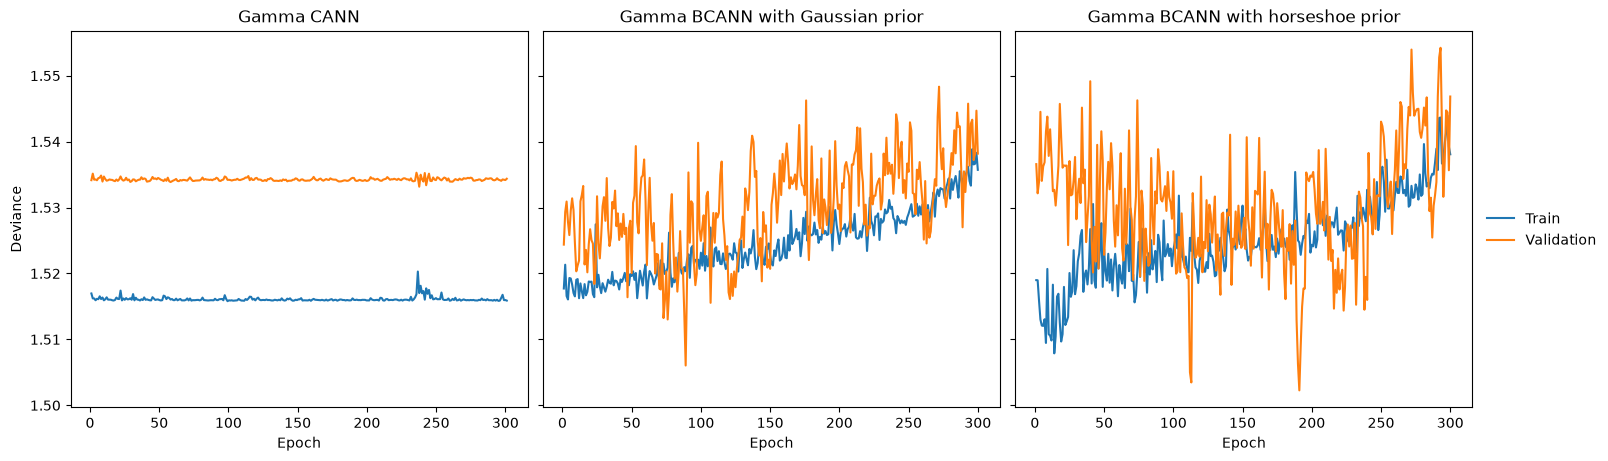

In [25]:
def unpack_bayes(h):
    ve = np.asarray(h["val_epochs"])
    tr = np.asarray(h["train_deviance"])
    x_tr = ve if len(tr) == len(ve) else np.arange(len(tr))
    return x_tr, tr, ve, np.asarray(h["val_deviance"])

# CANN
hc = cann_history_full
c_ve = np.linspace(1, 301, 300)
c_tr = np.asarray(hc["train_losses"])
c_x_tr = c_ve if len(c_tr) == len(c_ve) else np.arange(len(c_tr))
cann = (c_x_tr, c_tr, c_ve, np.asarray(hc["val_losses"]))

panels = [
    ("Gamma CANN", cann),
    ("Gamma BCANN with Gaussian prior", unpack_bayes(bcann_history_full)),
    ("Gamma BCANN with horseshoe prior", unpack_bayes(horseshoe_history_full)),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True, sharex=True,
                         layout="constrained")

for ax, (name, (x_tr, tr, x_val, val)) in zip(axes, panels):
    ax.plot(x_tr, tr, color="tab:blue", label="Train")
    ax.plot(x_val, val, color="tab:orange", label="Validation")
    ax.set_title(name)
    ax.set_xlabel("Epoch")

axes[0].set_ylabel("Deviance")

# single shared legend on the right of the whole figure
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside center right", frameon=False)

plt.show()

# fig.savefig("deviance_curves_all.pdf", bbox_inches="tight")_labels()
fig.legend(handles, labels, loc="outside center right", frameon=False)

plt.show()

# fig.savefig("deviance_curves_all.pdf", bbox_inches="tight")

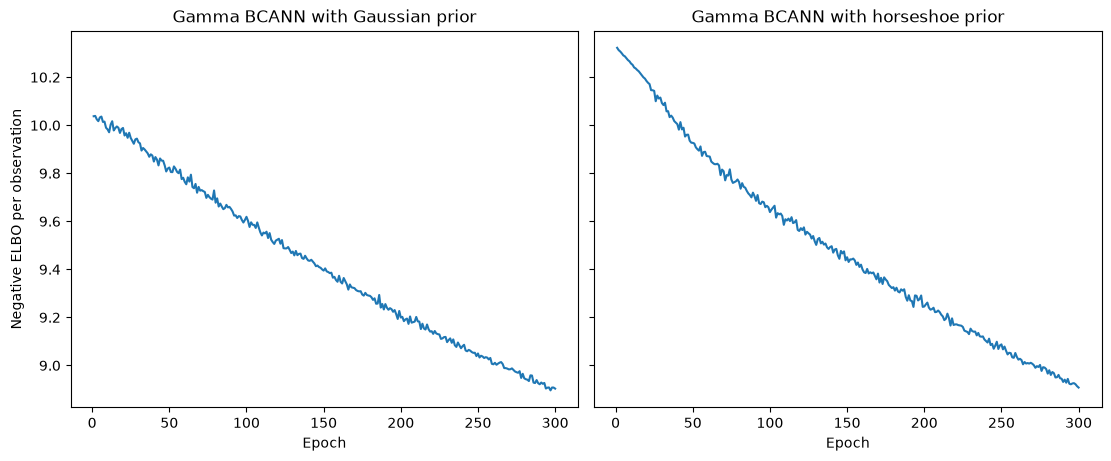

In [26]:
import numpy as np
import matplotlib.pyplot as plt

panels = [
    ("Gamma BCANN with Gaussian prior", bcann_history_full),
    ("Gamma BCANN with horseshoe prior", horseshoe_history_full),
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True, sharex=True,
                         layout="constrained")

for ax, (name, h) in zip(axes, panels):
    elbo = np.asarray(h["neg_elbo_per_obs"])
    ax.plot(np.arange(1, len(elbo) + 1), elbo, color="tab:blue")
    ax.set_title(name)
    ax.set_xlabel("Epoch")

axes[0].set_ylabel("Negative ELBO per observation")

plt.show()

# fig.savefig("neg_elbo_curves.pdf", bbox_inches="tight")

## Sensitive to sigma test

In [39]:
# sensitivity of prediction performance on value of sigma^2_w
sigma_sensi_scores = []
for sigma_sqrt in np.linspace(0.5, 3, 6):
    pyro.clear_param_store()
    
    set_seed(seed)
    model = GammaBCANN(
    in_features= 48,
    neural_net_params={"hidden_activation_nodes": network_architecture,
                        "hidden_activations": nn.Tanh,
                        "prior_scale": sigma_sqrt}).to(device)
    guide = gamma_build_bcann_guide(model, X_train[:256], y_train[:256], glm_mle=glm_mle, rank=10)
    bcann_history = gamma_bcann_svi_training_loop(
        model, guide, train_loader, val_loader,
        n_epochs=300, lr=5e-3, val_every=5, patience=10, 
        random_state=seed,
          device = device,
        kl_scheme = "uniform")
    sigma_sensi_scores.append({"sigma": sigma_sqrt, **bcann_history})

Shape warm-up: alpha held at 0.058 for 20 epochs


Epoch 1 | -ELBO/n: 10.4686 | train deviance: 1.5195 | val deviance: 1.5275 | alpha (median): 0.058 [warm-up]
Epoch 25 | -ELBO/n: 9.9707 | train deviance: 1.5187 | val deviance: 1.5254 | alpha (median): 0.060
Epoch 50 | -ELBO/n: 9.8550 | train deviance: 1.5206 | val deviance: 1.5281 | alpha (median): 0.069
Epoch 75 | -ELBO/n: 9.7281 | train deviance: 1.5213 | val deviance: 1.5223 | alpha (median): 0.079
Epoch 100 | -ELBO/n: 9.5974 | train deviance: 1.5249 | val deviance: 1.5255 | alpha (median): 0.090
Epoch 125 | -ELBO/n: 9.4874 | train deviance: 1.5223 | val deviance: 1.5357 | alpha (median): 0.104
Epoch 150 | -ELBO/n: 9.3993 | train deviance: 1.5208 | val deviance: 1.5181 | alpha (median): 0.119
Early stopping at epoch 155. Best val deviance 1.5104 at epoch 105
Shape warm-up: alpha held at 0.058 for 20 epochs
Epoch 1 | -ELBO/n: 10.0552 | train deviance: 1.5194 | val deviance: 1.5276 | alpha (median): 0.058 [warm-up]
Epoch 25 | -ELBO/n: 9.9019 | train deviance: 1.5187 | val deviance: 1